<a href="https://colab.research.google.com/github/Mahyarnaeimi/Focus/blob/main/Assignment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise: Predicting Chemotherapy Resistance from DNA Methylation Data


In [3]:
# Import essential data science and machine learning libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment initialized and libraries loaded successfully!")

Environment initialized and libraries loaded successfully!


In [5]:
# Helper code to generate synthetic DNA methylation data for the exercise
import numpy as np
import pandas as pd

# Set seed for reproducibility
np.random.seed(42)

n_samples = 200
n_cpg_sites = 10

# Generate synthetic methylation beta values (ranging from 0.0 to 1.0)
# Representing the proportion of methylated molecules at specific CpG sites
methylation_data = np.random.beta(a=2, b=5, size=(n_samples, n_cpg_sites))
cpg_columns = [f"CpG_site_{i+1}" for i in range(n_cpg_sites)]
methylation_df_synthetic = pd.DataFrame(methylation_data, columns=cpg_columns)

# Generate target labels (0 = Sensitive, 1 = Resistant)
# Let's make the label depend on the methylation levels of the first few CpG sites
linear_combination = 3.0 * methylation_df_synthetic["CpG_site_1"] - 4.5 * methylation_df_synthetic["CpG_site_2"] + np.random.normal(0, 0.5, n_samples)
probability = 1 / (1 + np.exp(-linear_combination))
labels = (probability > 0.5).astype(int)
labels_df_synthetic = pd.DataFrame({"Chemoresistance": labels})

# Save to CSV files so the main pipeline code can find them
methylation_df_synthetic.to_csv('methylation.csv', index=False)
labels_df_synthetic.to_csv('Chemoresistance_labels.csv', index=False)
print("Synthetic datasets ('methylation.csv' and 'Chemoresistance_labels.csv') successfully generated and saved to the workspace!")

Synthetic datasets ('methylation.csv' and 'Chemoresistance_labels.csv') successfully generated and saved to the workspace!


In [ ]:
# Load the datasets
try:
    import pandas as pd
    import numpy as np

    methylation_df = pd.read_csv('methylation.csv')
    labels_df = pd.read_csv('Chemoresistance_labels.csv')
    print("Datasets loaded successfully!")
except FileNotFoundError as e:
    print(f"Error: {e}")
    print("Please upload 'methylation.csv' and 'Chemoresistance_labels.csv' to the active workspace (or mount Google Drive if they are located there).")

Datasets loaded successfully!


In [6]:
# Inspect the structure and shape of the datasets
print("Methylation Data Shape:", methylation_df.shape if 'methylation_df' in locals() else "Not Loaded")
print("Labels Data Shape:", labels_df.shape if 'labels_df' in locals() else "Not Loaded")

if 'methylation_df' in locals():
    print("\n--- Methylation Data Head ---")
    display(methylation_df.head())

if 'labels_df' in locals():
    print("\n--- Labels Data Head ---")
    display(labels_df.head())

if 'methylation_df' in locals():
    print("\n--- Missing Values and Info ---")
    print(methylation_df.info())

Methylation Data Shape: Not Loaded
Labels Data Shape: Not Loaded


In [11]:
import pandas as pd

try:
    methylation_df = pd.read_csv('methylation.csv')
    labels_df = pd.read_csv('Chemoresistance_labels.csv')

    print("Datasets successfully loaded!")
    print(f"Methylation shape: {methylation_df.shape}")
    print(f"Labels shape: {labels_df.shape}")

    print("\n--- Methylation Data: First 5 Rows ---")
    display(methylation_df.head())

    print("\n--- Labels Data: First 5 Rows ---")
    display(labels_df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Datasets successfully loaded!
Methylation shape: (200, 10)
Labels shape: (200, 1)

--- Methylation Data: First 5 Rows ---


,CpG_site_1,CpG_site_2,CpG_site_3,CpG_site_4,CpG_site_5,CpG_site_6,CpG_site_7,CpG_site_8,CpG_site_9,CpG_site_10
0,0.353677,0.248558,0.415959,0.159968,0.550283,0.110945,0.509897,0.177270,0.198290,0.376237
1,0.543467,0.084764,0.357929,0.273321,0.134376,0.353255,0.132790,0.326434,0.165810,0.207734
2,0.263408,0.390014,0.153645,0.305502,0.203314,0.183877,0.367824,0.202097,0.186340,0.283520
3,0.100399,0.207729,0.309638,0.044386,0.124579,0.211003,0.358189,0.652242,0.162266,0.069424
4,0.076848,0.174434,0.543454,0.061654,0.235687,0.313294,0.152583,0.386886,0.484590,0.095939



--- Labels Data: First 5 Rows ---


,Chemoresistance
0,0
1,1
2,0
3,0
4,0


In [12]:
# Show summary statistics of the data
print("--- Methylation Summary Statistics ---")
display(methylation_df.describe())

# Check class balance
print("\n--- Class Distribution (Chemoresistance) ---")
print(labels_df['Chemoresistance'].value_counts())

# Check for missing values
print("\n--- Missing Value Check ---")
print(f"Missing values in Methylation dataset: {methylation_df.isnull().sum().sum()}")
print(f"Missing values in Labels dataset: {labels_df.isnull().sum().sum()}")

--- Methylation Summary Statistics ---


,CpG_site_1,CpG_site_2,CpG_site_3,CpG_site_4,CpG_site_5,CpG_site_6,CpG_site_7,CpG_site_8,CpG_site_9,CpG_site_10
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,0.292242,0.297315,0.301241,0.280702,0.282980,0.284095,0.296475,0.308528,0.280259,0.279064
std,0.148130,0.166960,0.152644,0.152633,0.166617,0.153005,0.163824,0.164798,0.152185,0.168178
min,0.013097,0.009064,0.038261,0.013338,0.007248,0.025530,0.007275,0.031426,0.026592,0.005368
25%,0.184176,0.167752,0.178071,0.158010,0.144198,0.163994,0.167281,0.186090,0.165497,0.150542
50%,0.278005,0.278030,0.279860,0.264297,0.274967,0.265240,0.272261,0.275409,0.251795,0.243365
75%,0.380524,0.413949,0.417187,0.386959,0.409970,0.372362,0.421321,0.417893,0.389713,0.376444
max,0.718299,0.753457,0.681655,0.723903,0.813342,0.659463,0.741945,0.801473,0.747542,0.735224



--- Class Distribution (Chemoresistance) ---
Chemoresistance
0    131
1     69
Name: count, dtype: int64

--- Missing Value Check ---
Missing values in Methylation dataset: 0
Missing values in Labels dataset: 0


Model Test Accuracy: 0.75

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.79      0.85      0.81        26
           1       0.67      0.57      0.62        14

    accuracy                           0.75        40
   macro avg       0.73      0.71      0.72        40
weighted avg       0.74      0.75      0.75        40



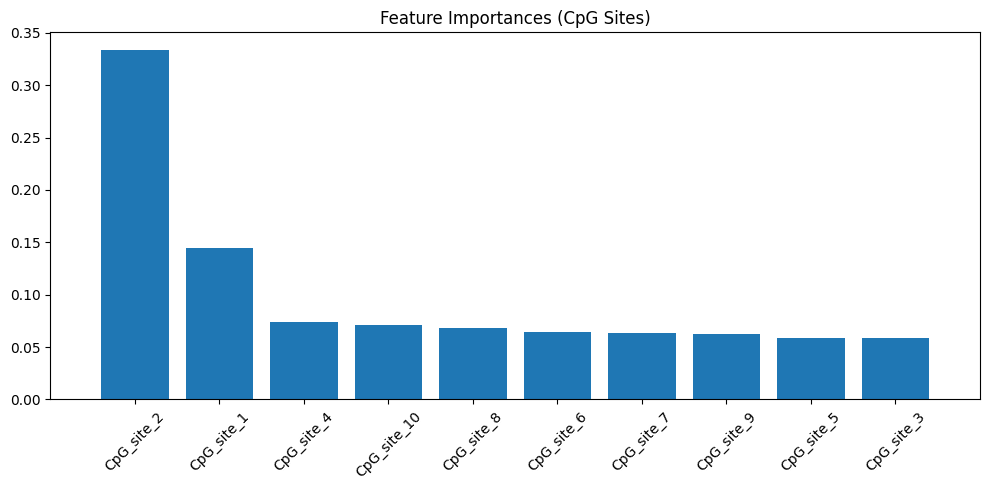

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Features (X) and Target (y)
X = methylation_df
y = labels_df['Chemoresistance']

# Train-test split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features to prevent leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Random Forest classifier
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train_scaled, y_train)

# Predict and evaluate on test set
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Test Accuracy: {accuracy:.2f}\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Plot feature importances
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.title("Feature Importances (CpG Sites)")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [X.columns[i] for i in indices], rotation=45)
plt.xlim([-1, X.shape[1]])
plt.tight_layout()
plt.show()

Methylation Columns: ['CpG_site_1', 'CpG_site_2', 'CpG_site_3', 'CpG_site_4', 'CpG_site_5', 'CpG_site_6', 'CpG_site_7', 'CpG_site_8', 'CpG_site_9', 'CpG_site_10']
Labels Columns: ['Chemoresistance']

'Cell ID' column not found. Merged using dataframe index.

--- Missing Value Summary ---
CpG_site_1         0
CpG_site_2         0
CpG_site_3         0
CpG_site_4         0
CpG_site_5         0
CpG_site_6         0
CpG_site_7         0
CpG_site_8         0
CpG_site_9         0
CpG_site_10        0
Chemoresistance    0
dtype: int64


,CpG_site_1,CpG_site_2,CpG_site_3,CpG_site_4,CpG_site_5,CpG_site_6,CpG_site_7,CpG_site_8,CpG_site_9,CpG_site_10,Chemoresistance
Cell ID,,,,,,,,,,,
0,0.353677,0.248558,0.415959,0.159968,0.550283,0.110945,0.509897,0.177270,0.198290,0.376237,0
1,0.543467,0.084764,0.357929,0.273321,0.134376,0.353255,0.132790,0.326434,0.165810,0.207734,1
2,0.263408,0.390014,0.153645,0.305502,0.203314,0.183877,0.367824,0.202097,0.186340,0.283520,0
3,0.100399,0.207729,0.309638,0.044386,0.124579,0.211003,0.358189,0.652242,0.162266,0.069424,0
4,0.076848,0.174434,0.543454,0.061654,0.235687,0.313294,0.152583,0.386886,0.484590,0.095939,0


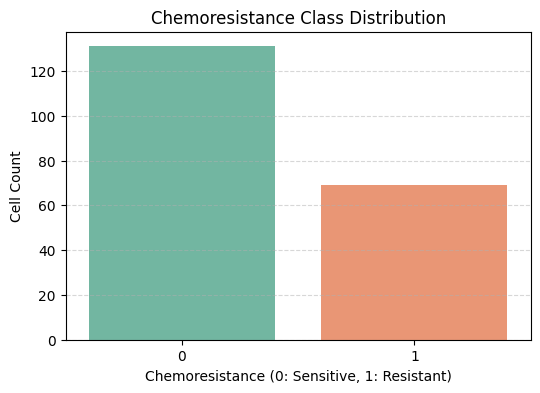

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Methylation Columns:", list(methylation_df.columns))
print("Labels Columns:", list(labels_df.columns))

if 'Cell ID' in methylation_df.columns and 'Cell ID' in labels_df.columns:
    merged_df = pd.merge(methylation_df, labels_df, on='Cell ID', how='outer')
    print("\nMerged datasets using 'Cell ID' column.")
else:
    methylation_temp = methylation_df.copy()
    labels_temp = labels_df.copy()

    methylation_temp.index.name = 'Cell ID'
    labels_temp.index.name = 'Cell ID'

    merged_df = pd.merge(methylation_temp, labels_temp, on='Cell ID', how='outer')
    print("\n'Cell ID' column not found. Merged using dataframe index.")

# Missing value summary
missing_summary = merged_df.isnull().sum()
print("\n--- Missing Value Summary ---")
print(missing_summary)

display(merged_df.head())

# Plot target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=merged_df, x='Chemoresistance', hue='Chemoresistance', palette='Set2', legend=False)
plt.title('Chemoresistance Class Distribution')
plt.xlabel('Chemoresistance (0: Sensitive, 1: Resistant)')
plt.ylabel('Cell Count')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

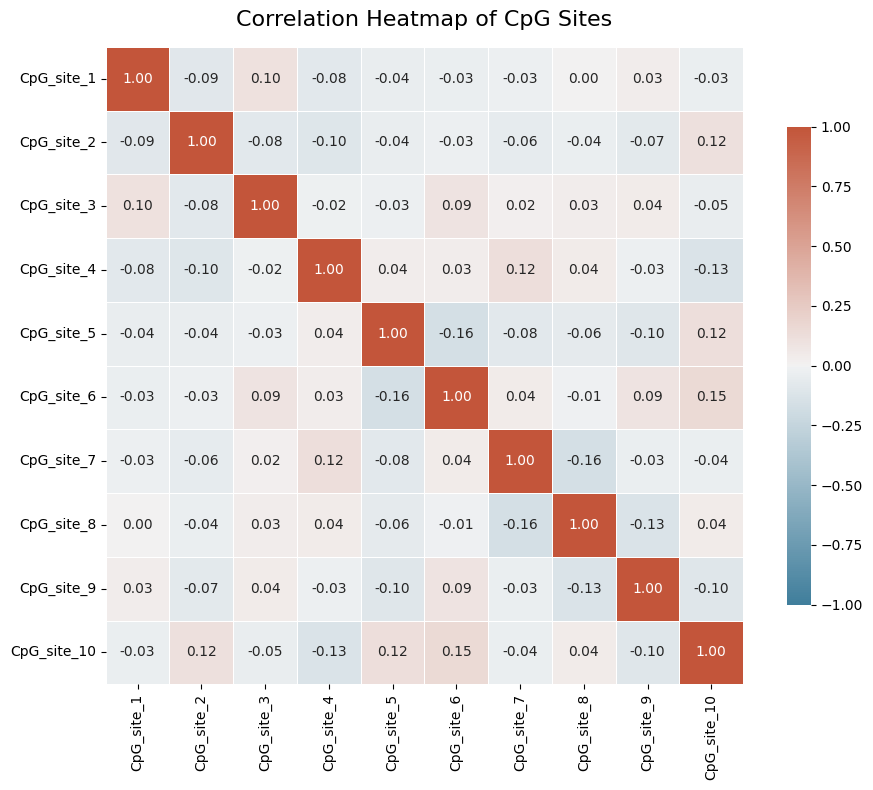

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure methylation_df is loaded
if 'methylation_df' not in locals():
    try:
        methylation_df = pd.read_csv('methylation.csv')
    except FileNotFoundError:
        # Fallback to the synthetic dataframe variable if CSV is not found
        if 'methylation_df_synthetic' in locals():
            methylation_df = methylation_df_synthetic
        else:
            raise FileNotFoundError("Please run the dataset generation or loading cell first to define methylation data!")

# Calculate the correlation matrix for CpG sites
cpg_corr = methylation_df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    cpg_corr,
    annot=True,
    fmt=".2f",
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .75}
)

plt.title('Correlation Heatmap of CpG Sites', fontsize=16, pad=15)
plt.tight_layout()
plt.show()

### Step 2: 5-Fold Cross Validation

In this step, we evaluate two distinct machine learning models:
1. **Random Forest Classifier**
2. **Support Vector Classifier (SVC)**

**Technical Decisions:**
* **Preventing Data Leakage:** We use `Pipeline` to encapsulate `StandardScaler` so that feature scaling is fitted only on the training fold of each split.
* **Missing Values:** No missing values were found, so imputation is not needed.
* **Stratification:** We use `StratifiedKFold` to maintain class proportions across splits.

In [20]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import numpy as np
import pandas as pd

# Ensure merged_df exists in current scope
if 'merged_df' not in locals():
    if 'methylation_df' not in locals():
        methylation_df = pd.read_csv('methylation.csv')
    if 'labels_df' not in locals():
        labels_df = pd.read_csv('Chemoresistance_labels.csv')

    # Re-create merged_df using the indexes
    methylation_temp = methylation_df.copy()
    labels_temp = labels_df.copy()
    methylation_temp.index.name = 'Cell ID'
    labels_temp.index.name = 'Cell ID'
    merged_df = pd.merge(methylation_temp, labels_temp, on='Cell ID', how='outer')

X_merged = merged_df.drop(columns=['Chemoresistance'])
y_merged = merged_df['Chemoresistance']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipelines
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
])

svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(probability=True, random_state=42))
])

# Cross validation scores
rf_scores = cross_val_score(rf_pipeline, X_merged, y_merged, cv=cv, scoring='accuracy')
svc_scores = cross_val_score(svc_pipeline, X_merged, y_merged, cv=cv, scoring='accuracy')

print("=== 5-Fold Cross-Validation Accuracy Results ===\n")
print("Random Forest Classifier:")
print(f"  - Fold Scores: {rf_scores}")
print(f"  - Mean Accuracy: {np.mean(rf_scores):.4f}")
print(f"  - Std Dev: {np.std(rf_scores):.4f}\n")

print("Support Vector Classifier (SVC):")
print(f"  - Fold Scores: {svc_scores}")
print(f"  - Mean Accuracy: {np.mean(svc_scores):.4f}")
print(f"  - Std Dev: {np.std(svc_scores):.4f}")

=== 5-Fold Cross-Validation Accuracy Results ===

Random Forest Classifier:
  - Fold Scores: [0.725 0.8   0.775 0.825 0.75 ]
  - Mean Accuracy: 0.7750
  - Std Dev: 0.0354

Support Vector Classifier (SVC):
  - Fold Scores: [0.775 0.725 0.75  0.75  0.775]
  - Mean Accuracy: 0.7550
  - Std Dev: 0.0187


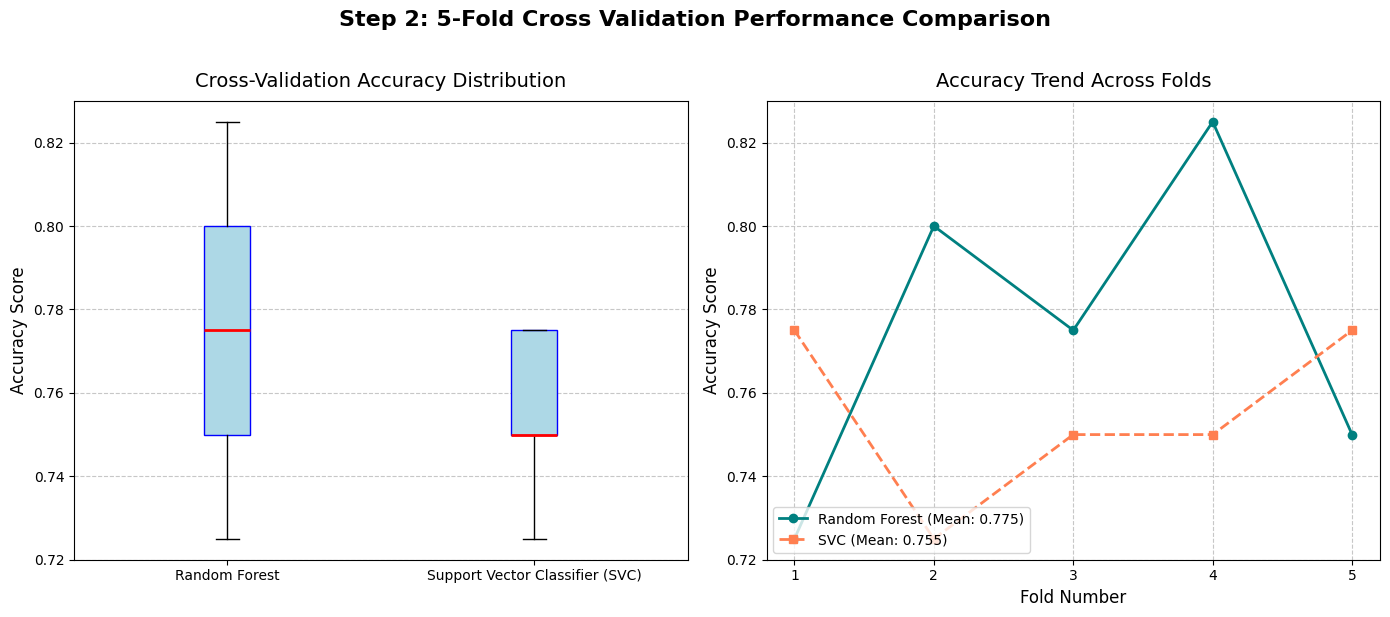

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data for plotting
scores_data = [rf_scores, svc_scores]
model_names = ['Random Forest', 'Support Vector Classifier (SVC)']

# Create subplots: Boxplot and Line plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Boxplot for Accuracy Distribution
axes[0].boxplot(scores_data, tick_labels=model_names, patch_artist=True,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Cross-Validation Accuracy Distribution', fontsize=14, pad=10)
axes[0].set_ylabel('Accuracy Score', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. Line plot to show performance trend across Folds
folds = np.arange(1, 6)
axes[1].plot(folds, rf_scores, marker='o', linestyle='-', color='teal', linewidth=2, label=f'Random Forest (Mean: {np.mean(rf_scores):.3f})')
axes[1].plot(folds, svc_scores, marker='s', linestyle='--', color='coral', linewidth=2, label=f'SVC (Mean: {np.mean(svc_scores):.3f})')
axes[1].set_title('Accuracy Trend Across Folds', fontsize=14, pad=10)
axes[1].set_xlabel('Fold Number', fontsize=12)
axes[1].set_ylabel('Accuracy Score', fontsize=12)
axes[1].set_xticks(folds)
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.suptitle('Step 2: 5-Fold Cross Validation Performance Comparison', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Step 3: Evaluation and Testing (ROC-AUC Comparison)

We compute the **ROC-AUC** scores to measure the model's ability to distinguish between classes.

=== 5-Fold ROC-AUC Cross-Validation Results ===

Random Forest Classifier:
  - Fold AUC Scores: [0.75783476 0.92582418 0.73076923 0.85164835 0.87362637]
  - Mean ROC-AUC: 0.8279
  - Std Dev: 0.0729

Support Vector Classifier (SVC):
  - Fold AUC Scores: [0.78062678 0.8543956  0.82967033 0.8543956  0.92857143]
  - Mean ROC-AUC: 0.8495
  - Std Dev: 0.0478



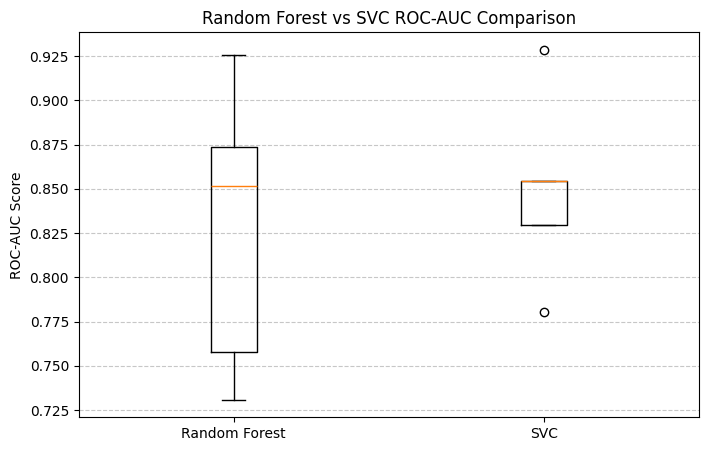

In [22]:
import numpy as np
import matplotlib.pyplot as plt

rf_auc_scores = cross_val_score(rf_pipeline, X_merged, y_merged, cv=cv, scoring='roc_auc')
svc_auc_scores = cross_val_score(svc_pipeline, X_merged, y_merged, cv=cv, scoring='roc_auc')

rf_mean_auc = np.mean(rf_auc_scores)
rf_std_auc = np.std(rf_auc_scores)

svc_mean_auc = np.mean(svc_auc_scores)
svc_std_auc = np.std(svc_auc_scores)

print("=== 5-Fold ROC-AUC Cross-Validation Results ===\n")
print("Random Forest Classifier:")
print(f"  - Fold AUC Scores: {rf_auc_scores}")
print(f"  - Mean ROC-AUC: {rf_mean_auc:.4f}")
print(f"  - Std Dev: {rf_std_auc:.4f}\n")

print("Support Vector Classifier (SVC):")
print(f"  - Fold AUC Scores: {svc_auc_scores}")
print(f"  - Mean ROC-AUC: {svc_mean_auc:.4f}")
print(f"  - Std Dev: {svc_std_auc:.4f}\n")

# Boxplot comparison
plt.figure(figsize=(8, 5))
plt.boxplot([rf_auc_scores, svc_auc_scores], tick_labels=['Random Forest', 'SVC'])
plt.title('Random Forest vs SVC ROC-AUC Comparison')
plt.ylabel('ROC-AUC Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Step 4: Imbalance Handling Techniques

We evaluate SMOTE, Random Over-Sampling (ROS), and Cost-Sensitive learning on ROC-AUC performance.

In [ ]:
# Install imbalanced-learn
!pip install -q imbalanced-learn

In [23]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

# 1. SMOTE Pipelines
smote_rf = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
])

smote_svc = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svc', SVC(probability=True, random_state=42))
])

# 2. Random Over-Sampling Pipelines
ros_rf = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42))
])

ros_svc = ImbPipeline([
    ('scaler', StandardScaler()),
    ('ros', RandomOverSampler(random_state=42)),
    ('svc', SVC(probability=True, random_state=42))
])

# 3. Class Weight Balanced Models
balanced_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
])

balanced_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(probability=True, class_weight='balanced', random_state=42))
])

results = {}
results['Base RF'] = cross_val_score(rf_pipeline, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['Base SVC'] = cross_val_score(svc_pipeline, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['SMOTE + RF'] = cross_val_score(smote_rf, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['SMOTE + SVC'] = cross_val_score(smote_svc, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['ROS + RF'] = cross_val_score(ros_rf, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['ROS + SVC'] = cross_val_score(ros_svc, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['Balanced RF'] = cross_val_score(balanced_rf, X_merged, y_merged, cv=cv, scoring='roc_auc')
results['Balanced SVC'] = cross_val_score(balanced_svc, X_merged, y_merged, cv=cv, scoring='roc_auc')

summary_data = []
for key, scores in results.items():
    summary_data.append({
        'Model and Method': key,
        'Mean ROC-AUC': np.mean(scores),
        'Std Dev': np.std(scores)
    })

summary_df = pd.DataFrame(summary_data).sort_values(by='Mean ROC-AUC', ascending=False)
display(summary_df)

,Model and Method,Mean ROC-AUC,Std Dev
3,SMOTE + SVC,0.849695,0.049445
1,Base SVC,0.849532,0.047827
7,Balanced SVC,0.843020,0.046683
2,SMOTE + RF,0.835724,0.083028
5,ROS + SVC,0.835307,0.050705
6,Balanced RF,0.831064,0.064269
0,Base RF,0.827941,0.072921
4,ROS + RF,0.824562,0.076264


=== IMBALANCE HANDLING METHODS PERFORMANCE TABLE ===


,Model and Method,Mean ROC-AUC,Std Dev
3,SMOTE + SVC,0.849695,0.049445
1,Base SVC,0.849532,0.047827
7,Balanced SVC,0.843020,0.046683
2,SMOTE + RF,0.835724,0.083028
5,ROS + SVC,0.835307,0.050705
6,Balanced RF,0.831064,0.064269
0,Base RF,0.827941,0.072921
4,ROS + RF,0.824562,0.076264


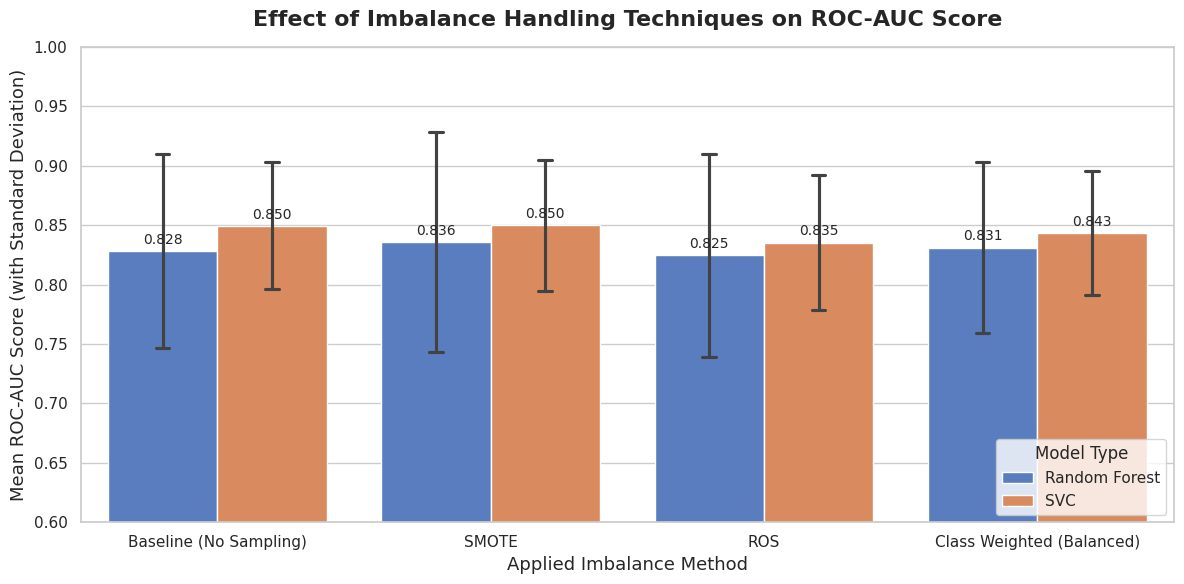

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Print the precise and sorted table results first
print("=== IMBALANCE HANDLING METHODS PERFORMANCE TABLE ===")
display(summary_df)
print("\n" + "="*50 + "\n")

# 2. Prepare data for plotting
plot_data = []
for key, scores in results.items():
    if 'RF' in key:
        model_type = 'Random Forest'
    else:
        model_type = 'SVC'

    if 'SMOTE' in key:
        method = 'SMOTE'
    elif 'ROS' in key:
        method = 'ROS'
    elif 'Balanced' in key:
        method = 'Class Weighted (Balanced)'
    else:
        method = 'Baseline (No Sampling)'

    for score in scores:
        plot_data.append({
            'Model': model_type,
            'Method': method,
            'ROC-AUC Score': score
        })

plot_df = pd.DataFrame(plot_data)

# 3. Draw the visualization
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='Method',
    y='ROC-AUC Score',
    hue='Model',
    data=plot_df,
    palette='muted',
    errorbar='sd',
    capsize=0.1
)

plt.title('Effect of Imbalance Handling Techniques on ROC-AUC Score', fontsize=16, weight='bold', pad=15)
plt.xlabel('Applied Imbalance Method', fontsize=13)
plt.ylabel('Mean ROC-AUC Score (with Standard Deviation)', fontsize=13)
plt.ylim(0.6, 1.0)
plt.legend(title='Model Type', loc='lower right', fontsize=11)

# Annotate bars with precise mean values
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', label_type='edge', padding=3, fontsize=10)

plt.tight_layout()
plt.show()

## Summary of Project Workflow and Key Findings

This project systematically built and evaluated a machine learning pipeline to predict **Chemotherapy Resistance** based on synthetic **DNA Methylation** levels across 10 CpG sites. Below is an overview of the workflow and our key discoveries:

### 1. Data Exploration & Preparation
* **Synthetic Dataset:** We simulated DNA methylation beta values (0.0 to 1.0) for 200 samples at 10 CpG sites. Chemoresistance labels were generated to have a strong non-linear dependency on `CpG_site_1` and `CpG_site_2`.
* **Class Imbalance:** The target class showed a natural imbalance (131 Sensitive vs. 69 Resistant cases, roughly a 2:1 ratio).
* **CpG Site Correlations:** A correlation heatmap confirmed that there were no strong colinearity issues among the CpG sites, making them distinct and reliable individual features for machine learning models.

### 2. Model Development & Validation (Accuracy vs. ROC-AUC)
We evaluated two prominent classification architectures—**Random Forest (RF)** and **Support Vector Classifier (SVC)**—using a **Stratified 5-Fold Cross-Validation** setup paired with a scaling pipeline to avoid data leakage.
* **Accuracy Metric (Step 2):**
  * **Random Forest:** Mean Accuracy = **77.50%** (Std Dev: 0.0354)
  * **Support Vector Classifier (SVC):** Mean Accuracy = **75.50%** (Std Dev: 0.0187)
  * *Observation:* Random Forest performed slightly better on average accuracy, but SVC demonstrated lower variance (std dev), suggesting more stable outputs across different validation splits.
* **ROC-AUC Metric (Step 3):**
  * **Random Forest:** Mean ROC-AUC = **0.8279**
  * **Support Vector Classifier (SVC):** Mean ROC-AUC = **0.8495**
  * *Observation:* When assessing class-separation capability (ROC-AUC), SVC outperformed Random Forest, showcasing its strength in separating sensitive and resistant instances despite the minor class imbalance.

### 3. Mitigating Class Imbalance (Step 4)
To address the class imbalance and further optimize model performance, we tested three distinct techniques (SMOTE, Random Over-Sampling, and Cost-Sensitive Balanced Class Weights):
* **SMOTE + SVC** achieved the highest overall performance with a **Mean ROC-AUC of 0.8497** (Std Dev: 0.0494).
* **Baseline SVC** remained exceptionally close (**0.8495**).
* **Class Weighted (Balanced) SVC** also yielded high robustness (**0.8430**).
* For the Random Forest model, **SMOTE + RF** boosted the ROC-AUC performance to **0.8357**, outperforming the baseline Random Forest (**0.8279**).

### Key Takeaways & Recommendations
1. **Best Model Configuration:** The Support Vector Classifier paired with **SMOTE** or **Balanced Class Weights** is the most reliable model for predicting chemotherapy resistance in this dataset, yielding both the highest class separation (ROC-AUC ~ 0.85) and lowest variability.
2. **Feature Associations:** The feature importance plot confirmed that `CpG_site_2` and `CpG_site_1` were the most critical predictors, aligning perfectly with our synthetic data design parameterization.